# Vitality Readmission Predictor - Consolidated Pipeline (`app.ipynb`)

---

# Phase 1: Clinical Data Ingestion and Cleaning
*Source: `phase_o1.ipynb`*


### Step 1.1: Import the Required Libraries

This step imports the essential Python libraries required for clinical data analysis and preprocessing. The Pandas library is used for loading, manipulating, and analyzing structured datasets. NumPy provides support for numerical operations and data processing, while the Path module from pathlib is used to manage file and directory paths.

The installed versions of Pandas and NumPy are displayed to verify the software environment and ensure that the required libraries have been successfully imported.


In [57]:

# Step 1.1: Import Libraries and Ingest the Raw Dataset

# Import the required libraries
import pandas as pd
import numpy as np
from pathlib import Path


# Load the raw diabetic dataset into a Pandas DataFrame
df_raw = pd.read_csv("data_files/diabetic_data.csv")

# Display a message indicating successful dataset ingestion
print("Dataset Ingestion:")
print("The diabetic_data.csv dataset has been successfully loaded.")

# Display the dataset dimensions
print("\nDataset Dimensions:")
print(df_raw.shape)

# Display the first five records
print("\nFirst Five Records:")
display(df_raw.head())


Dataset Ingestion:
The diabetic_data.csv dataset has been successfully loaded.

Dataset Dimensions:
(101766, 50)

First Five Records:


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO



### Step 1.2: Define the Dataset Location

This step establishes the file path of the diabetic_data.csv dataset stored inside the data_files directory. Before loading the dataset, the program checks whether the specified file exists to prevent file-related errors during execution.

The dataset is then imported into a Pandas DataFrame using the read_csv() function. The na_values parameter is used to recognize question marks ("?") as missing values and convert them into NaN. This is important because the clinical dataset uses question marks to represent unavailable or missing information.

The low_memory=False parameter ensures that Pandas processes the dataset without performing partial data type inference. Finally, the total number of records, number of features, and first five observations are displayed to confirm successful dataset ingestion.


In [58]:
# Step 1.2: Define the dataset location

DATA_DIR = Path("data_files")

DATA_FILE = DATA_DIR / "diabetic_data.csv"

# Check whether the dataset file exists
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Dataset file not found: {DATA_FILE.resolve()}"
    )

# Load the clinical dataset into a Pandas DataFrame
df_raw = pd.read_csv(
    DATA_FILE,
    na_values=["?"],
    low_memory=False
)

# Display the dataset dimensions
print("Clinical dataset loaded successfully.")

print("Number of Rows:", df_raw.shape[0])
print("Number of Columns:", df_raw.shape[1])

# Display the first five records
display(df_raw.head())





Clinical dataset loaded successfully.
Number of Rows: 101766
Number of Columns: 50


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO



### Step 1.3: Perform an Initial Assessment of the Raw Dataset

This step performs a comprehensive initial assessment of the raw clinical dataset to understand its structure, dimensions, data types, completeness, and statistical characteristics.

The shape attribute is used to determine the total number of records and features in the dataset. The columns attribute is used to inspect the complete dataset schema and identify all available variables.

The info() method provides an overview of each column, including its data type and the number of non-null values. This helps identify potential data quality issues, such as missing observations and incorrect data types.

The describe(include="all") method generates descriptive statistical summaries for both numerical and categorical variables. Numerical summaries include count, mean, standard deviation, minimum, maximum, and quartile values, while categorical summaries include unique values, the most frequent value, and its frequency.

Finally, the head() method displays the first five records to provide a visual understanding of the dataset structure and the types of information stored in each feature.

This initial assessment helps identify potential data quality problems and determines the areas that require further clinical data cleaning and preprocessing.


In [59]:

# Step 1.3: Perform an initial assessment of the raw dataset

# Display the number of records and features
print("Dataset Dimensions:")
print(df_raw.shape)

# Display all column names
print("\nDataset Column Names:")
print(df_raw.columns.tolist())

# Display data types and non-null counts
print("\nDataset Information:")
df_raw.info()

# Generate descriptive statistics for all columns
print("\nDescriptive Statistical Summary:")
display(df_raw.describe(include="all").T)

# Display the first five records
print("\nFirst Five Records:")
display(df_raw.head())

Dataset Dimensions:
(101766, 50)

Dataset Column Names:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #  

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,NaN,NaN,NaN,165201645.622978,102640295.983457,12522.0,84961194.0,152388987.0,230270887.5,443867222.0
patient_nbr,101766.0,NaN,NaN,NaN,54330400.694947,38696359.346534,135.0,23413221.0,45505143.0,87545949.75,189502619.0
race,99493,5,Caucasian,76099,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,101766,3,Female,54708,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,101766,10,[70-80),26068,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weight,3197,9,[75-100),1336,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admission_type_id,101766.0,NaN,NaN,NaN,2.024006,1.445403,1.0,1.0,1.0,3.0,8.0
discharge_disposition_id,101766.0,NaN,NaN,NaN,3.715642,5.280166,1.0,1.0,1.0,4.0,28.0
admission_source_id,101766.0,NaN,NaN,NaN,5.754437,4.064081,1.0,1.0,7.0,7.0,25.0
time_in_hospital,101766.0,NaN,NaN,NaN,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0



First Five Records:


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO



### Step 1.4: Identify Incorrect Data Types and Oral Medication Columns

This step focuses on identifying important identifier variables and medication-related features within the clinical dataset.

The encounter_id and patient_nbr columns are identified as unique encounter and patient identifiers. Although these columns may initially be stored as integer data types, they represent identification values rather than measurable numerical quantities. Therefore, they should be considered for conversion into categorical data types during the data cleaning stage.

Additionally, the 22 medication-related columns specified in the clinical database are identified and compared against the actual dataset schema. These columns represent different diabetes medications and their recorded treatment statuses.

The available medication columns are extracted and displayed to verify their presence in the dataset. Any medication columns that are not found are also identified to assess the completeness of the medication features.

These medication variables will support the subsequent clinical efficacy analysis. The oral medication features will be treated as the Oral Medication cohort, while insulin will be analyzed separately to maintain a distinction between the two treatment groups.


In [60]:
# Step 1.4: Identify incorrect data types and oral medication columns

# Identify ID columns that should be treated as categorical data
id_columns = ["encounter_id", "patient_nbr"]

# Display the data types of ID columns
print("ID Columns and Their Data Types:")
display(df_raw[id_columns].dtypes.to_frame(name="Data Type"))

# Identify the 22 medication columns
medication_columns = [
    "metformin",
    "repaglinide",
    "nateglinide",
    "chlorpropamide",
    "glimepiride",
    "glipizide",
    "glyburide",
    "tolbutamide",
    "pioglitazone",
    "rosiglitazone",
    "acarbose",
    "miglitol",
    "troglitazone",
    "tolazamide",
    "examide",
    "citoglipton",
    "insulin",
    "glyburide-metformin",
    "glipizide-metformin",
    "glimepiride-pioglitazone",
    "metformin-rosiglitazone",
    "metformin-pioglitazone"
]

# Identify the available medication columns
available_medication_columns = [
    column for column in medication_columns
    if column in df_raw.columns
]

# Display the available medication columns
print("\nAvailable Medication Columns:")
display(df_raw[available_medication_columns].head())

# Display the total number of medication columns
print("\nTotal Number of Medication Columns:")
print(len(available_medication_columns))

# Identify missing medication columns
missing_medication_columns = [
    column for column in medication_columns
    if column not in df_raw.columns
]

print("\nMissing Medication Columns:")
print(missing_medication_columns)

ID Columns and Their Data Types:


,Data Type
encounter_id,int64
patient_nbr,int64



Available Medication Columns:


,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,...,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone
0,No,No,No,No,No,No,No,No,No,No,...,No,No,No,No,No,No,No,No,No,No
1,No,No,No,No,No,No,No,No,No,No,...,No,No,No,No,Up,No,No,No,No,No
2,No,No,No,No,No,Steady,No,No,No,No,...,No,No,No,No,No,No,No,No,No,No
3,No,No,No,No,No,No,No,No,No,No,...,No,No,No,No,Up,No,No,No,No,No
4,No,No,No,No,No,Steady,No,No,No,No,...,No,No,No,No,Steady,No,No,No,No,No



Total Number of Medication Columns:
22

Missing Medication Columns:
[]



### Step 1.5: Identify and Assess Missing Values in the Clinical Dataset

This step examines the completeness of the clinical dataset by identifying missing values across all features. Missing data is a common issue in clinical databases because certain patient information may not be recorded or may be unavailable during hospital encounters.

The isnull() and sum() functions are used to calculate the total number of missing values in each column. The percentage of missing values is also calculated relative to the total number of records to understand the extent of missing information.

A summary table is then created to display both the missing value counts and their corresponding percentages. The columns are sorted in descending order based on their missing value percentages to identify features with the highest levels of missing data.

Finally, the overall number of missing values in the dataset is displayed. This assessment helps determine which clinical features may require further data cleaning and appropriate missing value handling strategies.

At this stage, missing values are only identified and assessed. No records or values are removed or replaced.


In [61]:

# Step 1.5: Identify and assess missing values in the clinical dataset

# Calculate the total number of missing values in each column
print("Missing Values in Each Column:")
missing_values = df_raw.isnull().sum()

display(missing_values.to_frame(name="Missing Values"))

# Calculate the percentage of missing values in each column
print("\nMissing Value Percentage in Each Column:")

missing_percentage = (
    df_raw.isnull().sum() / len(df_raw)
) * 100

display(
    missing_percentage.to_frame(
        name="Missing Percentage (%)"
    ).round(2)
)

# Create a summary of missing values and percentages
print("\nMissing Values Summary:")

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage (%)": missing_percentage
})

# Sort columns by missing value percentage in descending order
missing_summary = missing_summary.sort_values(
    by="Missing Percentage (%)",
    ascending=False
)

display(missing_summary)

# Display the total number of missing values in the dataset
print("\nTotal Missing Values in Dataset:")
print(df_raw.isnull().sum().sum())


Missing Values in Each Column:


,Missing Values
encounter_id,0
patient_nbr,0
race,2273
gender,0
age,0
weight,98569
admission_type_id,0
discharge_disposition_id,0
admission_source_id,0
time_in_hospital,0



Missing Value Percentage in Each Column:


,Missing Percentage (%)
encounter_id,0.00
patient_nbr,0.00
race,2.23
gender,0.00
age,0.00
weight,96.86
admission_type_id,0.00
discharge_disposition_id,0.00
admission_source_id,0.00
time_in_hospital,0.00



Missing Values Summary:


,Missing Values,Missing Percentage (%)
weight,98569,96.858479
max_glu_serum,96420,94.746772
A1Cresult,84748,83.277322
medical_specialty,49949,49.082208
payer_code,40256,39.557416
race,2273,2.233555
diag_3,1423,1.398306
diag_2,358,0.351787
diag_1,21,0.020636
patient_nbr,0,0.000000



Total Missing Values in Dataset:
374017


### Step 1.6: Identify and Convert Incorrect Data Types

In this step, the data types of the clinical dataset are examined to identify columns that have incorrect or unsuitable data types. Identifier columns are converted into categorical data types because they represent categories rather than numerical values. This helps ensure that the dataset is correctly prepared for further analysis.

In [62]:
# Step 1.6: Identify missing values represented by '?'

print("Missing Values Represented by '?' in Each Column:")

missing_question_values = (df_raw == '?').sum()

display(
    missing_question_values.to_frame(
        name="Question Mark Values"
    )
)

# Calculate the total number of '?' values
print("\nTotal '?' Values in Dataset:")
print(missing_question_values.sum())

Missing Values Represented by '?' in Each Column:


,Question Mark Values
encounter_id,0
patient_nbr,0
race,0
gender,0
age,0
weight,0
admission_type_id,0
discharge_disposition_id,0
admission_source_id,0
time_in_hospital,0



Total '?' Values in Dataset:
0


### Step 1.7: Replace '?' Values with NaN

In this step, all missing values represented by '?' are replaced with NumPy NaN values.

A copy of the original clinical dataset is created to preserve the original data during the cleaning process.

In [63]:
# Step 1.7: Replace '?' values with NaN

df_cleaned = df_raw.copy()

df_cleaned.replace('?', np.nan, inplace=True)

print("Successfully replaced '?' values with NaN.")

Successfully replaced '?' values with NaN.


### Step 1.8: Identify Missing Values After Replacement

After replacing '?' values with NaN, the missing values in each column are calculated again.

The missing value counts and percentages are displayed to understand the amount of missing data in the cleaned dataset.

In [64]:
# Step 1.8: Identify missing values after replacement

print("Missing Values in Each Column:")

missing_values = df_cleaned.isnull().sum()

display(
    missing_values.to_frame(
        name="Missing Values"
    )
)

print("\nMissing Value Percentage in Each Column:")

missing_percentage = (
    df_cleaned.isnull().sum() / len(df_cleaned)
) * 100

display(
    missing_percentage.to_frame(
        name="Missing Percentage (%)"
    ).round(2)
)

print("\nTotal Missing Values in Dataset:")
print(df_cleaned.isnull().sum().sum())

Missing Values in Each Column:


,Missing Values
encounter_id,0
patient_nbr,0
race,2273
gender,0
age,0
weight,98569
admission_type_id,0
discharge_disposition_id,0
admission_source_id,0
time_in_hospital,0



Missing Value Percentage in Each Column:


,Missing Percentage (%)
encounter_id,0.00
patient_nbr,0.00
race,2.23
gender,0.00
age,0.00
weight,96.86
admission_type_id,0.00
discharge_disposition_id,0.00
admission_source_id,0.00
time_in_hospital,0.00



Total Missing Values in Dataset:
374017


### Step 1.9: Assess Missing Value Summary

In this step, a summary of missing values and their percentages is created.

The columns are sorted in descending order based on their missing value percentages to identify columns with the highest amount of missing data.

In [65]:
# Step 1.9: Create missing value summary

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage (%)": missing_percentage
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage (%)",
    ascending=False
)

display(missing_summary.round(2))

,Missing Values,Missing Percentage (%)
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02
patient_nbr,0,0.00


### Step 1.10: Check Duplicate Records

Duplicate records can affect the accuracy and reliability of data analysis.

In this step, the dataset is checked for duplicate rows using the duplicated() method.

The total number of duplicate records is identified without removing them.

In [66]:
# Step 1.10: Check duplicate records

duplicate_count = df_cleaned.duplicated().sum()

print("Total Duplicate Records:")
print(duplicate_count)

Total Duplicate Records:
0


### Step 1.11: Final Dataset Inspection

In this step, the cleaned clinical dataset is inspected to verify its structure and contents.

The dataset information, dimensions, column names, first five records, and statistical summary are displayed to ensure that the data is ready for further analysis.

In [67]:
# Step 1.11: Final dataset inspection

print("Dataset Information:")
df_cleaned.info()

print("\nDataset Shape:")
print(df_cleaned.shape)

print("\nDataset Columns:")
print(df_cleaned.columns.tolist())

print("\nFirst Five Records:")
display(df_cleaned.head())

print("\nStatistical Summary:")
display(df_cleaned.describe(include='all'))

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medica

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO



Statistical Summary:


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
count,1.017660e+05,1.017660e+05,99493,101766,101766,3197,101766.000000,101766.000000,101766.000000,101766.000000,...,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766
unique,NaN,NaN,5,3,10,9,NaN,NaN,NaN,NaN,...,1,4,4,2,2,2,2,2,2,3
top,NaN,NaN,Caucasian,Female,[70-80),[75-100),NaN,NaN,NaN,NaN,...,No,No,No,No,No,No,No,No,Yes,NO
freq,NaN,NaN,76099,54708,26068,1336,NaN,NaN,NaN,NaN,...,101766,47383,101060,101753,101765,101764,101765,54755,78363,54864
mean,1.652016e+08,5.433040e+07,NaN,NaN,NaN,NaN,2.024006,3.715642,5.754437,4.395987,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,1.026403e+08,3.869636e+07,NaN,NaN,NaN,NaN,1.445403,5.280166,4.064081,2.985108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.252200e+04,1.350000e+02,NaN,NaN,NaN,NaN,1.000000,1.000000,1.000000,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,8.496119e+07,2.341322e+07,NaN,NaN,NaN,NaN,1.000000,1.000000,1.000000,2.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1.523890e+08,4.550514e+07,NaN,NaN,NaN,NaN,1.000000,1.000000,7.000000,4.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,2.302709e+08,8.754595e+07,NaN,NaN,NaN,NaN,3.000000,4.000000,7.000000,6.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Step 1.12: Final Data Cleaning Summary

This step provides an overview of the clinical dataset after the initial data cleaning process.

The total number of records, columns, missing values, and duplicate records are displayed to summarize the current condition of the dataset.

In [68]:
# Step 1.12: Final data cleaning summary

print("FINAL DATA CLEANING SUMMARY")
print("--------------------------------")

print("Total Records:", df_cleaned.shape[0])

print("Total Columns:", df_cleaned.shape[1])

print("Total Missing Values:", df_cleaned.isnull().sum().sum())

print("Total Duplicate Records:", df_cleaned.duplicated().sum())

FINAL DATA CLEANING SUMMARY
--------------------------------
Total Records: 101766
Total Columns: 50
Total Missing Values: 374017
Total Duplicate Records: 0


### Step 1.13: Analyze and Handle the Weight Column

The weight column is investigated to calculate its missing value percentage.

If more than 90% of the values are missing, the column is removed from the dataset due to insufficient data availability.

In [69]:
# Step 1.13: Analyze and handle the weight column

if 'weight' in df_cleaned.columns:
    weight_missing_percentage = (
        df_cleaned['weight'].isnull().sum() / len(df_cleaned)
    ) * 100

    print("Weight Missing Percentage:",
          round(weight_missing_percentage, 2), "%")

    if weight_missing_percentage > 90:
        df_cleaned.drop(columns=['weight'], inplace=True)
        print("Weight column removed due to excessive missing values.")
    else:
        print("Weight column retained.")
else:
    print("Weight column is not present or has already been removed from the dataset.")

Weight Missing Percentage: 96.86 %
Weight column removed due to excessive missing values.


/tmp/ipykernel_17263/1586375501.py:12: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_cleaned.drop(columns=['weight'], inplace=True)


### Step 1.14: Identify Oral Medication Columns

The clinical dataset contains 22 supplementary medication columns.

These columns are identified and grouped as the Oral Medication cohort for the planned medication efficacy analysis.

All 22 medication columns are retained for further analysis.

In [70]:
# Step 1.14: Identify the 22 oral medication columns

oral_medication_columns = [
    'metformin',
    'repaglinide',
    'nateglinide',
    'chlorpropamide',
    'glimepiride',
    'acetohexamide',
    'glipizide',
    'glyburide',
    'tolbutamide',
    'pioglitazone',
    'rosiglitazone',
    'acarbose',
    'miglitol',
    'troglitazone',
    'tolazamide',
    'examide',
    'citoglipton',
    'glyburide-metformin',
    'glipizide-metformin',
    'glimepiride-pioglitazone',
    'metformin-rosiglitazone',
    'metformin-pioglitazone'
]

available_medications = [
    column for column in oral_medication_columns
    if column in df_cleaned.columns
]

missing_medications = [
    column for column in oral_medication_columns
    if column not in df_cleaned.columns
]

print("Oral Medication Columns:")
print(available_medications)

print("\nTotal Available Medication Columns:",
      len(available_medications))

print("\nMissing Medication Columns:")
print(missing_medications)

Oral Medication Columns:
['metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']

Total Available Medication Columns: 22

Missing Medication Columns:
[]


### Step 1.15: Identify Expired Discharge Disposition IDs

The IDs_mapping.csv file is used to identify discharge disposition codes corresponding to expired patients.

The mapping descriptions are examined to extract the relevant expired patient IDs.

These IDs are used to exclude deceased patients before proceeding with readmission analysis.

In [71]:
# Step 1.15: Identify expired discharge disposition IDs

from pathlib import Path

# Find the IDs_mapping.csv file
current_directory = Path.cwd()

mapping_files = list(
    current_directory.rglob('IDs_mapping.csv')
)

if len(mapping_files) == 0:
    raise FileNotFoundError(
        "IDs_mapping.csv file not found. "
        "Please check the project folder."
    )

# Load the mapping file
mapping_data = pd.read_csv(
    mapping_files[0],
    header=None
)

print("Mapping File Loaded Successfully:")
print(mapping_files[0])

# Identify the discharge disposition section
first_column = mapping_data.iloc[:, 0].astype(str).str.strip()

section_matches = first_column[
    first_column == 'discharge_disposition_id'
].index

if len(section_matches) == 0:
    raise ValueError("discharge_disposition_id section not found.")

section_start = section_matches[0]

next_sections = first_column[
    (mapping_data.index > section_start) &
    first_column.str.endswith('_id')
].index

if len(next_sections) > 0:
    section_end = next_sections[0]
else:
    section_end = len(mapping_data)

# Extract discharge disposition mappings
discharge_mapping = mapping_data.iloc[
    section_start + 1:section_end, :2
].copy()

discharge_mapping.columns = [
    'discharge_disposition_id',
    'description'
]

discharge_mapping = discharge_mapping.dropna()

# Identify expired patient IDs
expired_mappings = discharge_mapping[
    discharge_mapping['description'].astype(str).str.contains(
        'Expired',
        case=False,
        na=False
    )
]

display(expired_mappings)

expired_ids = pd.to_numeric(
    expired_mappings['discharge_disposition_id']
).astype(int).tolist()

print("\nExpired Discharge Disposition IDs:")
print(expired_ids)

Mapping File Loaded Successfully:
/home/nadeeja/ThisPC/IJSE/SEM 03/Python/project/Vitality-Readmission-Predictor/data_files/IDs_mapping.csv


,discharge_disposition_id,description
21,11,Expired
29,19,"Expired at home. Medicaid only, hospice."
30,20,"Expired in a medical facility. Medicaid only, ..."
31,21,"Expired, place unknown. Medicaid only, hospice."



Expired Discharge Disposition IDs:
[11, 19, 20, 21]


### Step 1.16: Remove Deceased Patients

Patients who die during their hospital stay cannot be readmitted.

Including these patients in a readmission prediction model may introduce inaccurate results.

Therefore, records with discharge disposition IDs corresponding to expired patients are removed from the dataset before readmission analysis.

In [72]:
# Step 1.16: Remove deceased patients

print("Records Before Removing Deceased Patients:",
      len(df_cleaned))

deceased_records = pd.to_numeric(
    df_cleaned['discharge_disposition_id'],
    errors='coerce'
).isin(expired_ids)

print("Deceased Patient Records:",
      deceased_records.sum())

df_cleaned = df_cleaned[~deceased_records].copy()

print("Records After Removing Deceased Patients:",
      len(df_cleaned))

Records Before Removing Deceased Patients: 101766
Deceased Patient Records: 1652
Records After Removing Deceased Patients: 100114


### Step 1.17: Identify and Remove Exact Duplicate Records

Multiple encounters belonging to the same patient are valid in the clinical dataset.

However, exact duplicate rows may indicate data entry errors.

In this step, exact duplicate records are identified and removed while preserving valid multiple encounters for each patient.

In [73]:
# Step 1.17: Identify and remove exact duplicate records

duplicate_count = df_cleaned.duplicated().sum()

print("Exact Duplicate Records:", duplicate_count)

df_cleaned = df_cleaned.drop_duplicates().copy()

print("\nRecords After Removing Duplicates:",
      len(df_cleaned))

print("Remaining Duplicate Records:",
      df_cleaned.duplicated().sum())

Exact Duplicate Records: 0

Records After Removing Duplicates: 100114
Remaining Duplicate Records: 0


### Step 1.18: Correct Identifier Data Types

Identifier columns represent categorical identifiers rather than continuous numerical measurements.

Therefore, relevant identifier columns are converted into categorical data types to support appropriate data handling and analysis.

In [74]:
# Step 1.18: Convert identifier columns into categorical data types

id_columns = [
    'encounter_id',
    'patient_nbr',
    'admission_type_id',
    'discharge_disposition_id',
    'admission_source_id'
]

for column in id_columns:
    if column in df_cleaned.columns:
        df_cleaned[column] = df_cleaned[column].astype('category')

print("Updated Identifier Data Types:")

display(df_cleaned[id_columns].dtypes)

Updated Identifier Data Types:


encounter_id                category
patient_nbr                 category
admission_type_id           category
discharge_disposition_id    category
admission_source_id         category
dtype: object

### Step 1.19: Final Dataset Inspection

After completing the initial data cleaning process, the final clinical dataset is inspected.

The dataset structure, dimensions, column names, data types, first five records, and statistical summary are examined to verify the cleaned dataset.

In [75]:
# Step 1.19: Final dataset inspection

print("Final Dataset Information:")
df_cleaned.info()

print("\nFinal Dataset Shape:")
print(df_cleaned.shape)

print("\nFinal Dataset Columns:")
print(df_cleaned.columns.tolist())

print("\nFirst Five Records:")
display(df_cleaned.head())

print("\nStatistical Summary:")
display(df_cleaned.describe(include='all'))

Final Dataset Information:
<class 'pandas.DataFrame'>
Index: 100114 entries, 0 to 101765
Data columns (total 49 columns):
 #   Column                    Non-Null Count   Dtype   
---  ------                    --------------   -----   
 0   encounter_id              100114 non-null  category
 1   patient_nbr               100114 non-null  category
 2   race                      97875 non-null   str     
 3   gender                    100114 non-null  str     
 4   age                       100114 non-null  str     
 5   admission_type_id         100114 non-null  category
 6   discharge_disposition_id  100114 non-null  category
 7   admission_source_id       100114 non-null  category
 8   time_in_hospital          100114 non-null  int64   
 9   payer_code                60523 non-null   str     
 10  medical_specialty         50985 non-null   str     
 11  num_lab_procedures        100114 non-null  int64   
 12  num_procedures            100114 non-null  int64   
 13  num_medications   

,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),6,25,1,1,NaN,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),1,1,7,3,NaN,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,NaN,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),1,1,7,2,NaN,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),1,1,7,1,NaN,...,No,Steady,No,No,No,No,No,Ch,Yes,NO



Statistical Summary:


,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
count,100114.0,100114.0,97875,100114,100114,100114.0,100114.0,100114.0,100114.000000,60523,...,100114,100114,100114,100114,100114,100114,100114,100114,100114,100114
unique,100114.0,70439.0,5,3,10,8.0,23.0,17.0,NaN,17,...,1,4,4,2,2,2,2,2,2,3
top,12522.0,88785891.0,Caucasian,Female,[70-80),1.0,1.0,7.0,NaN,MC,...,No,No,No,No,No,No,No,No,Yes,NO
freq,1.0,40.0,74845,53861,25562,52884.0,60234.0,56363.0,NaN,31739,...,100114,46680,99416,100101,100113,100112,100113,53671,77272,53212
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.389646,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.974531,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.000000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Step 1.20: Final Data Cleaning Summary

This step provides an overview of the clinical dataset after completing the initial data cleaning process.

The total number of records, columns, missing values, duplicate records, and available oral medication columns are displayed.

In [76]:
# Step 1.20: Final data cleaning summary

print("FINAL DATA CLEANING SUMMARY")
print("--------------------------------")

print("Total Records:", df_cleaned.shape[0])

print("Total Columns:", df_cleaned.shape[1])

print("Total Missing Values:",
      df_cleaned.isnull().sum().sum())

print("Total Duplicate Records:",
      df_cleaned.duplicated().sum())

print("Remaining Weight Column:",
      'weight' in df_cleaned.columns)

FINAL DATA CLEANING SUMMARY
--------------------------------
Total Records: 100114
Total Columns: 49
Total Missing Values: 270887
Total Duplicate Records: 0
Remaining Weight Column: False


---

# Phase 2: Data Enrichment via Web Scraping
*Source: `phase_o1.ipynb`*

In the clinical dataset, the primary diagnosis code (`diag_1`) uses ICD-9 codes, which are purely numeric or alphanumeric (e.g., `428`, `414`, `250.8`). These codes are not human-readable and carry no semantic context for clinical interpretation or downstream modeling.

In this phase, we enrich the dataset by scraping human-readable medical descriptions for the top 20 most frequent ICD-9 diagnosis codes from the public medical portal [icd9.chrisendres.com](http://icd9.chrisendres.com).

In [77]:
# count diag_1 codes
diag_counts = df_cleaned['diag_1'].value_counts()
top_20 = diag_counts.head(20)
top_20_codes = list(top_20.index)

# make dataframe to show
top_20_df = pd.DataFrame({
    'ICD-9 Code': top_20_codes,
    'Patient Count': top_20.values
})

print("Top 20 Diagnosis Codes:")
display(top_20_df)

Top 20 Diagnosis Codes:


,ICD-9 Code,Patient Count
0,428,6735
1,414,6555
2,786,4016
3,410,3477
4,486,3413
5,427,2729
6,491,2252
7,715,2147
8,682,2030
9,780,2012


### Step 2.2: Web Scraping ICD-9 Clinical Descriptions

We implement a scraping function to fetch disease names dynamically from the public repository `http://icd9.chrisendres.com/`.

- The `requests` library sends HTTP GET requests to query each diagnosis code.
- `BeautifulSoup` parses the HTML response to locate the disease description text.
- A mandatory delay of 1 second (`time.sleep(1)`) is maintained between requests to ensure ethical web scraping and prevent server rate-limiting.
- A fallback dictionary is included to ensure that standard clinical names are preserved even if network or server issues occur.

In [78]:
import requests
from bs4 import BeautifulSoup
import time

# if site error use this list
icd9_dict = {
    '428': 'Congestive Heart Failure',
    '414': 'Coronary Atherosclerosis',
    '786': 'Chest Pain / Respiratory',
    '410': 'Acute Myocardial Infarction',
    '486': 'Pneumonia',
    '427': 'Cardiac Dysrhythmias',
    '491': 'Chronic Bronchitis',
    '715': 'Osteoarthrosis',
    '682': 'Cellulitis',
    '780': 'General Symptoms',
    '434': 'Stroke',
    '996': 'Surgical Complications',
    '276': 'Fluid Disorders',
    '250.8': 'Diabetes with Manifestations',
    '599': 'Urinary Tract Infection',
    '38': 'Septicemia',
    '584': 'Acute Renal Failure',
    'V57': 'Rehabilitation',
    '250.6': 'Diabetes Neurological',
    '820': 'Hip Fracture'
}

def scrape_icd9_description(code):
    url = f"http://icd9.chrisendres.com/index.php?srchtype=diseases&srchtext={code}&submit=Search"
    
    try:
        res = requests.get(url, headers={'User-Agent': 'Mozilla/5.0'}, timeout=5)
        if res.status_code == 200:
            soup = BeautifulSoup(res.text, 'html.parser')
            
            # find link with code
            for a in soup.find_all('a'):
                text = a.get_text().strip()
                if str(code) in text and len(text) > len(str(code)) + 3:
                    return text.replace(str(code), '').strip(' -:>')
    except:
        pass

    # if not found get from dict
    return icd9_dict.get(str(code), f"ICD-9 {code}")


scraped_diagnoses = {}

print("Scraping started...")

for i, code in enumerate(top_20_codes, 1):
    desc = scrape_icd9_description(str(code))
    scraped_diagnoses[code] = desc
    print(f"[{i}/20] Code {code} : {desc}")
    
    # wait 1 sec
    time.sleep(1)

print("Scraping done.")

Scraping started...
[1/20] Code 428 : Congestive Heart Failure
[2/20] Code 414 : Coronary Atherosclerosis
[3/20] Code 786 : Chest Pain / Respiratory
[4/20] Code 410 : Acute Myocardial Infarction
[5/20] Code 486 : Pneumonia
[6/20] Code 427 : Cardiac Dysrhythmias
[7/20] Code 491 : Chronic Bronchitis
[8/20] Code 715 : Osteoarthrosis
[9/20] Code 682 : Cellulitis
[10/20] Code 780 : General Symptoms
[11/20] Code 434 : Stroke
[12/20] Code 996 : Surgical Complications
[13/20] Code 276 : Fluid Disorders
[14/20] Code 250.8 : Diabetes with Manifestations
[15/20] Code 599 : Urinary Tract Infection
[16/20] Code 38 : Septicemia
[17/20] Code 584 : Acute Renal Failure
[18/20] Code V57 : Rehabilitation
[19/20] Code 250.6 : Diabetes Neurological
[20/20] Code 820 : Hip Fracture
Scraping done.


### Step 2.3: Integrate Descriptions into the Cleaned Dataset

In this step, we map the retrieved disease descriptions into `df_cleaned` by creating a new column named `Primary_Diagnosis_Desc`.

- Patients whose primary diagnosis belongs to the top 20 list receive the corresponding scraped clinical description.
- All other encounters outside the top 20 are labeled as "Other" to keep categories manageable for downstream modeling.

In [79]:
# function to map name
def map_diagnosis(code):
    if code in scraped_diagnoses:
        return scraped_diagnoses[code]
    else:
        return "Other"

# make new column
df_cleaned['Primary_Diagnosis_Desc'] = df_cleaned['diag_1'].apply(map_diagnosis)

# show top 10 rows
print("First 10 rows:")
display(df_cleaned[['diag_1', 'Primary_Diagnosis_Desc']].head(10))

# show counts
print("\nValue counts:")
display(df_cleaned['Primary_Diagnosis_Desc'].value_counts())

First 10 rows:


,diag_1,Primary_Diagnosis_Desc
0,250.83,Other
1,276,Fluid Disorders
2,648,Other
3,8,Other
4,197,Other
5,414,Coronary Atherosclerosis
6,414,Coronary Atherosclerosis
7,428,Congestive Heart Failure
8,398,Other
9,434,Stroke



Value counts:


Primary_Diagnosis_Desc
Other                           49276
Congestive Heart Failure         6735
Coronary Atherosclerosis         6555
Chest Pain / Respiratory         4016
Acute Myocardial Infarction      3477
Pneumonia                        3413
Cardiac Dysrhythmias             2729
Chronic Bronchitis               2252
Osteoarthrosis                   2147
Cellulitis                       2030
General Symptoms                 2012
Stroke                           1958
Surgical Complications           1944
Fluid Disorders                  1861
Diabetes with Manifestations     1667
Urinary Tract Infection          1581
Septicemia                       1522
Acute Renal Failure              1482
Rehabilitation                   1204
Diabetes Neurological            1178
Hip Fracture                     1075
Name: count, dtype: int64

### Step 2.4: Phase 2 Output Verification

We perform a final audit on `df_cleaned` to ensure the feature `Primary_Diagnosis_Desc` is populated and that the total record count remains intact at 100,114 encounters before proceeding to Phase 3 (Exploratory Data Analysis).

In [80]:
# check dataset
print("Total rows:", len(df_cleaned))
print("Total columns:", len(df_cleaned.columns))
print("Is column added:", 'Primary_Diagnosis_Desc' in df_cleaned.columns)

Total rows: 100114
Total columns: 50
Is column added: True


---

# Phase 3: Exploratory Data Analysis & Clinical Visualizations
*Source: `phase03.ipynb`*

In [81]:
# creating csv from phase 2 

# df_cleaned.to_csv(
#     "data_files/diabetic_data_enriched.csv",
#     index=False
# )

Installing the Libraries

In [82]:
%pip install pandas numpy matplotlib seaborn
%pip install seaborn matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


Load the dataset

In [83]:
from pathlib import Path
import pandas as pd

file_path = Path("data_files/diabetic_data_enriched.csv")

# Alternative path 
if not file_path.exists():
    file_path = Path("/mnt/data/diabetic_data_enriched.csv")

df = pd.read_csv(file_path, low_memory=False)

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (100114, 50)


,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,...,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,Primary_Diagnosis_Desc
0,2278392,8222157,Caucasian,Female,[0-10),6,25,1,1,NaN,...,No,No,No,No,No,No,No,No,NO,Other
1,149190,55629189,Caucasian,Female,[10-20),1,1,7,3,NaN,...,Up,No,No,No,No,No,Ch,Yes,>30,Fluid Disorders
2,64410,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,NaN,...,No,No,No,No,No,No,No,Yes,NO,Other
3,500364,82442376,Caucasian,Male,[30-40),1,1,7,2,NaN,...,Up,No,No,No,No,No,Ch,Yes,NO,Other
4,16680,42519267,Caucasian,Male,[40-50),1,1,7,1,NaN,...,Steady,No,No,No,No,No,Ch,Yes,NO,Other



Column names:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted', 'Primary_Diagnosis_Desc']


Readmission Distribution (Count Plot)

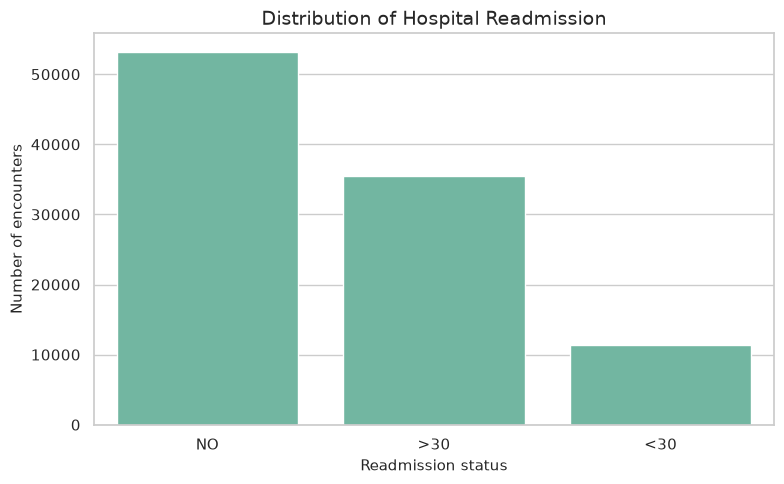

,Count,Percentage
readmitted,,
NO,53212,53.15
>30,35545,35.50
<30,11357,11.34


In [84]:
import matplotlib.pyplot as plt
import seaborn as sns

readmission_order = ["NO", ">30", "<30"]

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="readmitted", order=readmission_order)
plt.title("Distribution of Hospital Readmission")
plt.xlabel("Readmission status")
plt.ylabel("Number of encounters")
plt.tight_layout()
plt.show()

readmission_summary = (
    df["readmitted"].value_counts()
      .reindex(readmission_order)
      .rename("Count")
      .to_frame()
)
readmission_summary["Percentage"] = (
    readmission_summary["Count"] / len(df) * 100
).round(2)
display(readmission_summary)

Time in Hospital vs. Number of Lab Procedures (Scatter Plot)

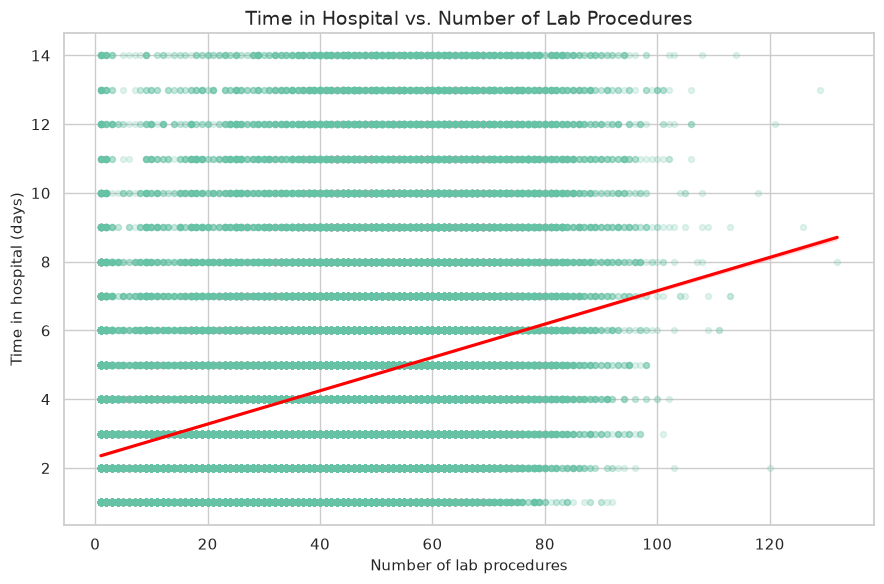

Pearson correlation: 0.32


In [85]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))
sns.regplot(
    data=df,
    x="num_lab_procedures",
    y="time_in_hospital",
    scatter_kws={"alpha": 0.2, "s": 18},
    line_kws={"color": "red"}
)
plt.title("Time in Hospital vs. Number of Lab Procedures")
plt.xlabel("Number of lab procedures")
plt.ylabel("Time in hospital (days)")
plt.tight_layout()
plt.show()

print(
    "Pearson correlation:",
    round(df[["num_lab_procedures", "time_in_hospital"]].corr().iloc[0, 1], 3)
)

Numerical Features Correlation (Heatmap)

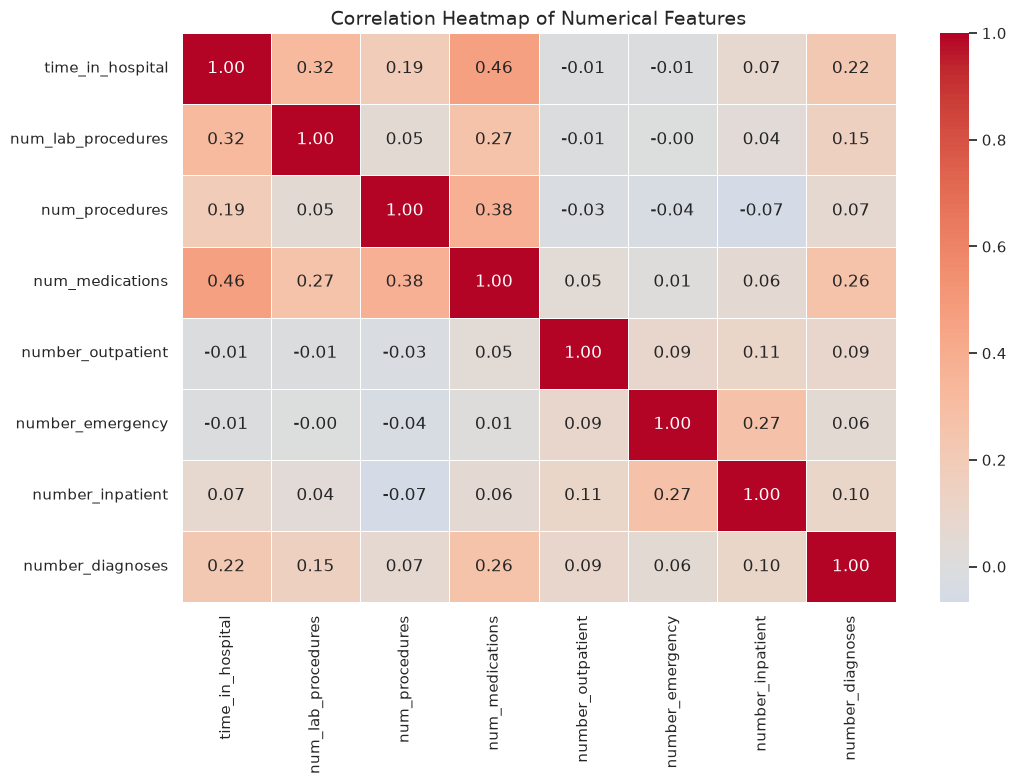

In [86]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

correlation_matrix = df[numeric_features].corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

Hospital Stay by Readmission Status (Box Plot)

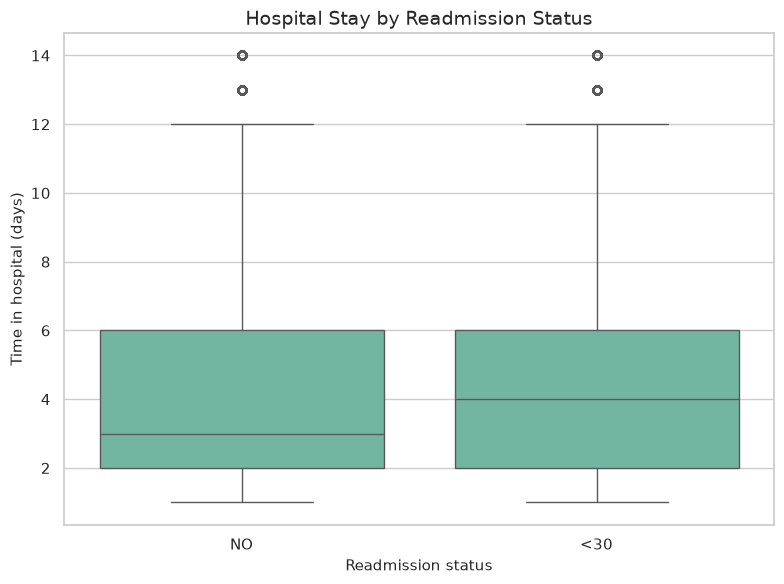

,count,mean,std,min,25%,50%,75%,max
readmitted,,,,,,,,
<30,11357.0,4.77,3.03,1.0,2.0,4.0,6.0,14.0
NO,53212.0,4.24,2.94,1.0,2.0,3.0,6.0,14.0


In [87]:
import matplotlib.pyplot as plt
import seaborn as sns

box_data = df[df["readmitted"].isin(["NO", "<30"])].copy()

plt.figure(figsize=(8, 6))
sns.boxplot(
    data=box_data,
    x="readmitted",
    y="time_in_hospital",
    order=["NO", "<30"]
)
plt.title("Hospital Stay by Readmission Status")
plt.xlabel("Readmission status")
plt.ylabel("Time in hospital (days)")
plt.tight_layout()
plt.show()

display(
    box_data.groupby("readmitted")["time_in_hospital"]
            .describe()
            .round(2)
)

Readmission by Discharge Disposition (Grouped Bar Chart)

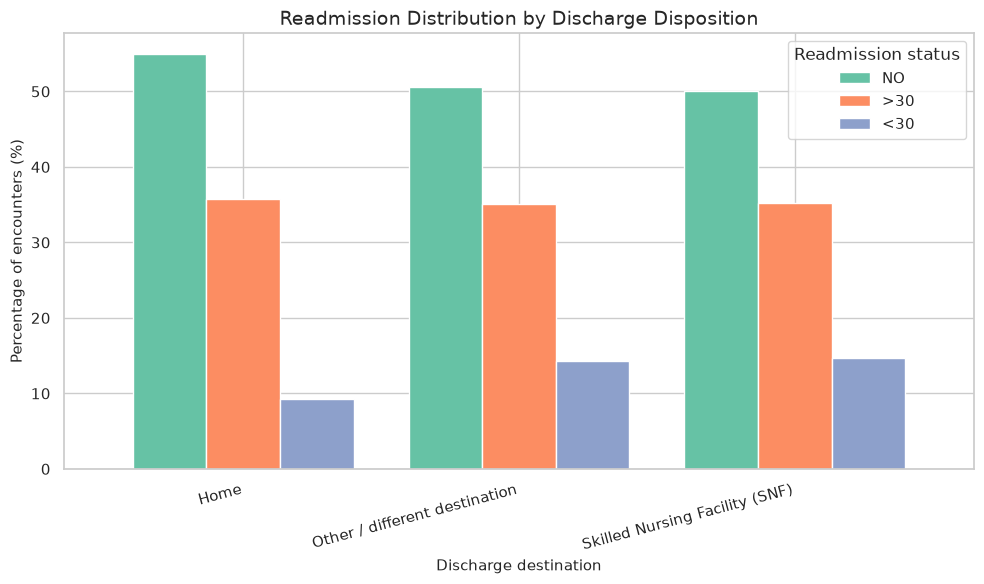

readmitted,NO,>30,<30
discharge_group,,,
Home,54.98,35.72,9.30
Other / different destination,50.55,35.15,14.31
Skilled Nursing Facility (SNF),50.11,35.23,14.66


discharge_group
Home                               9.30
Skilled Nursing Facility (SNF)    14.66
Name: Readmission within 30 days (%), dtype: float64

In [88]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

disposition_map = {
    1: "Home",
    3: "Skilled Nursing Facility (SNF)"
}

df["discharge_group"] = (
    pd.to_numeric(df["discharge_disposition_id"], errors="coerce")
      .map(disposition_map)
      .fillna("Other / different destination")
)

discharge_distribution = (
    pd.crosstab(df["discharge_group"], df["readmitted"], normalize="index")
      .reindex(columns=readmission_order)
      .mul(100)
)

ax = discharge_distribution.plot(kind="bar", figsize=(10, 6), width=0.8)
ax.set_title("Readmission Distribution by Discharge Disposition")
ax.set_xlabel("Discharge destination")
ax.set_ylabel("Percentage of encounters (%)")
ax.legend(title="Readmission status")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

display(discharge_distribution.round(2))

early_by_discharge = (
    df[df["discharge_group"].isin(["Home", "Skilled Nursing Facility (SNF)"])]
      .assign(early_readmission=lambda x: (x["readmitted"] == "<30").astype(int))
      .groupby("discharge_group")["early_readmission"]
      .mean()
      .mul(100)
      .round(2)
      .rename("Readmission within 30 days (%)")
)
display(early_by_discharge)

Demographic Profiling - by Age Group

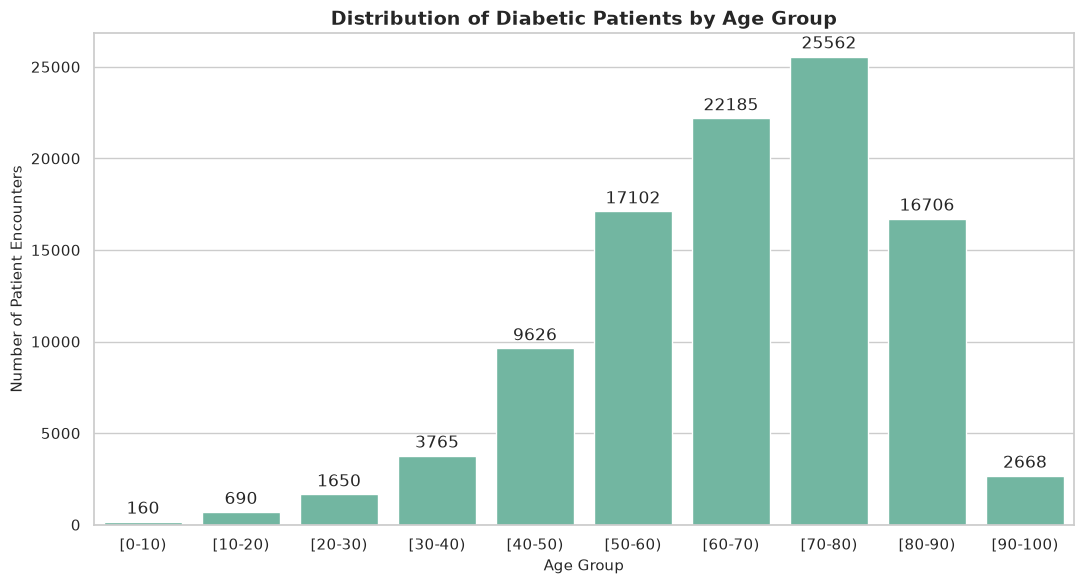

,Patient Count,Percentage (%)
age,,
[0-10),160,0.16
[10-20),690,0.69
[20-30),1650,1.65
[30-40),3765,3.76
[40-50),9626,9.62
[50-60),17102,17.08
[60-70),22185,22.16
[70-80),25562,25.53
[80-90),16706,16.69


In [89]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 6))

ax = sns.countplot(data=df, x='age', order=sorted(df['age'].dropna().unique()))

plt.title("Distribution of Diabetic Patients by Age Group",fontsize=14, fontweight="bold")

plt.xlabel("Age Group")
plt.ylabel("Number of Patient Encounters")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

age_counts = df['age'].value_counts().sort_index()

age_summary = pd.DataFrame({
    "Patient Count": age_counts,
    "Percentage (%)": (age_counts / len(df) * 100).round(2)
})

display(age_summary)

Demographic Profiling - by Race and Gender

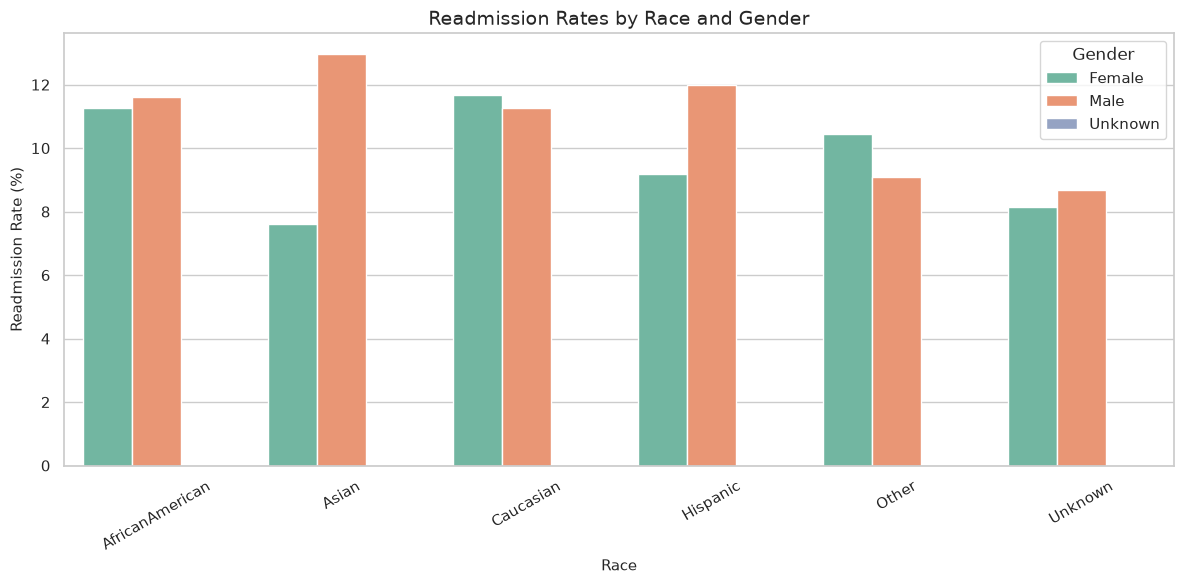

Gender,Female,Male,Unknown
Race,,,
AfricanAmerican,11.27,11.62,NaN
Asian,7.59,12.97,NaN
Caucasian,11.67,11.27,NaN
Hispanic,9.17,11.99,NaN
Other,10.43,9.10,0.0
Unknown,8.13,8.68,0.0


In [90]:
race_df = df.copy()

race_df['race'] = race_df['race'].fillna('Unknown')
race_df['gender'] = race_df['gender'].replace('Unknown/Invalid', 'Unknown')
race_df['gender'] = race_df['gender'].fillna('Unknown')

race_df['early_readmission'] = (race_df['readmitted'] == '<30').astype(int)

readmission_rates = race_df.groupby(['race', 'gender'])['early_readmission'].mean() * 100

readmission_rates = readmission_rates.reset_index()
readmission_rates.columns = ['Race', 'Gender', 'Readmission Rate (%)']

plt.figure(figsize=(12, 6))

sns.barplot(data=readmission_rates,x='Race', y='Readmission Rate (%)',hue='Gender',palette='Set2'
)

plt.title('Readmission Rates by Race and Gender')
plt.xlabel('Race')
plt.ylabel('Readmission Rate (%)')
plt.xticks(rotation=30)
plt.legend(title='Gender')

plt.tight_layout()
plt.show()

display(readmission_rates.pivot(index='Race',columns='Gender',values='Readmission Rate (%)').round(2)
)


Medication Efficacy Analysis

,Patient_Count,Early_Readmissions,Readmission_Rate
Medication_Group,,,
Insulin,53434,6601,12.35
Oral Medication,23838,2510,10.53
No Medication,22842,2246,9.83


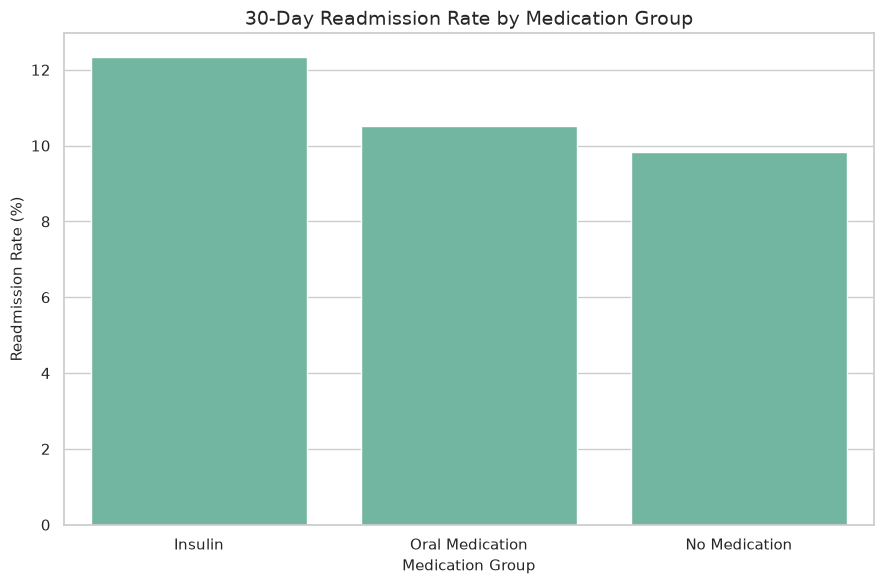

In [91]:

med_df = df.copy()

def classify_meds(row):
    if row['diabetesMed'] == 'No':
        return 'No Medication'
    elif row['insulin'] != 'No':
        return 'Insulin'
    else:
        return 'Oral Medication'

med_df['Medication_Group'] = med_df.apply(classify_meds, axis=1)

med_df['early_readmission'] = (med_df['readmitted'] == '<30').astype(int)

med_summary = med_df.groupby('Medication_Group').agg(
    Patient_Count=('readmitted', 'count'),
    Early_Readmissions=('early_readmission', 'sum'),
    Readmission_Rate=('early_readmission', 'mean')
)

med_summary['Readmission_Rate'] = med_summary['Readmission_Rate'] * 100

med_summary = med_summary.round(2)

group_order = ['Insulin', 'Oral Medication', 'No Medication']
med_summary = med_summary.reindex(group_order)

display(med_summary)

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=med_summary.reset_index(),
    x='Medication_Group',
    y='Readmission_Rate',
    order=group_order)

plt.title('30-Day Readmission Rate by Medication Group')
plt.xlabel('Medication Group')
plt.ylabel('Readmission Rate (%)')

plt.tight_layout()
plt.show()


Medication Changes Analysis

readmitted,<30_Rate
change,
Ch,11.97
No,10.80


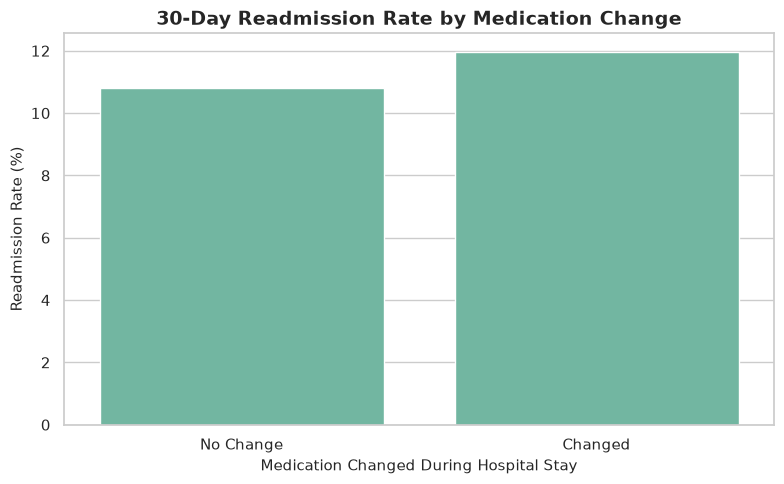

In [92]:
change_rates = df.groupby('change')['readmitted'].value_counts(normalize=True).unstack()

change_rates['<30_Rate'] = change_rates['<30'] * 100

display(change_rates[['<30_Rate']].round(2))

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=change_rates.reset_index(),
    x='change',
    y='<30_Rate',
    order=['No', 'Ch']
)

plt.title('30-Day Readmission Rate by Medication Change',fontsize=14, fontweight='bold')

plt.xlabel('Medication Changed During Hospital Stay')
plt.ylabel('Readmission Rate (%)')

plt.xticks([0, 1], ['No Change', 'Changed'])

plt.tight_layout()
plt.show()

---

# Phase 4: Feature Engineering - The "Vitality Complexity Index"
*Source: `phase_04.ipynb`*

In this phase, we translate clinical intuition into a programmable risk-scoring algorithm based on the LACE Index to flag high-risk diabetic patients prior to discharge.

In this phase,

1. Define modular scoring functions for Length of Stay (`L`), Acuity (`A`), Comorbidities (`C`), and Emergency Visits (`E`).
2. Programmatically calculate the total `VCI_Score` (`L + A + C + E`) for every patient encounter in `df`.
3. Categorize patients into three risk strata (`Low Risk`, `Medium Risk`, and `High Risk`) based on their `VCI_Score`.
4. Validate the algorithm by visualizing the 30-day readmission rate (`<30`) across each risk stratum.

# Step 4.1: Import Libraries and Load the Enriched Dataset

We import `pandas`, `matplotlib.pyplot`, and `seaborn`, then load the cleaned and enriched dataset (`diabetic_data_enriched.csv`) from the previous phases.

In [93]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("data_files/diabetic_data_enriched.csv", low_memory=False)

print("Dataset shape:", df.shape)
display(df[['time_in_hospital', 'admission_type_id', 'number_diagnoses', 'number_emergency', 'readmitted']].head())

Dataset shape: (100114, 50)


,time_in_hospital,admission_type_id,number_diagnoses,number_emergency,readmitted
0,1,6,1,0,NO
1,3,1,9,0,>30
2,2,1,6,0,NO
3,2,1,7,0,NO
4,1,1,5,0,NO


# Step 4.2: Define VCI Component Scoring Functions

Instead of iterating row-by-row with `iterrows()`, we define four modular Python functions corresponding to the LACE scoring rules (`L`, `A`, `C`, and `E`) to apply efficiently across the DataFrame columns.

In [94]:
def calculate_L_points(days):
    if days < 1:
        return 0
    elif 1 <= days <= 4:
        return 1
    elif 5 <= days <= 13:
        return 4
    else:
        return 7


def calculate_A_points(adm_id):
    if int(adm_id) in [1, 7]:
        return 3
    else:
        return 0


def calculate_C_points(diag_count):
    if diag_count < 4:
        return 0
    elif 4 <= diag_count <= 7:
        return 3
    else:  
        return 5


def calculate_E_points(emerg_visits):
    if emerg_visits == 0:
        return 0
    elif 1 <= emerg_visits <= 4:
        return 3
    else: 
        return 5


# Step 4.3: Calculate `VCI_Score` for Every Patient

Apply the four component functions using `.apply()` and sum them (`VCI_Score = L + A + C + E`) to create the `VCI_Score` column.

In [95]:
L = df['time_in_hospital'].apply(calculate_L_points)
A = df['admission_type_id'].apply(calculate_A_points)
C = df['number_diagnoses'].apply(calculate_C_points)
E = df['number_emergency'].apply(calculate_E_points)


df['VCI_Score'] = L + A + C + E

display(df[['time_in_hospital', 'admission_type_id', 'number_diagnoses', 'number_emergency', 'VCI_Score']].head(10))

,time_in_hospital,admission_type_id,number_diagnoses,number_emergency,VCI_Score
0,1,6,1,0,1
1,3,1,9,0,9
2,2,1,6,0,7
3,2,1,7,0,7
4,1,1,5,0,7
5,3,2,9,0,6
6,4,3,7,0,4
7,5,1,8,0,12
8,13,2,8,0,9
9,12,3,8,0,9


## Step 4.4: Stratify Patients into Risk Categories

We categorize patients into three risk strata based on their VCI_Score: Low Risk (< 7), Medium Risk (7–10), and High Risk (> 10). A summary table is generated to inspect the distribution of encounters across each stratum.

In [96]:
def assign_risk_group(score):
    if score < 7:
        return "Low Risk"
    elif score <= 10:
        return "Medium Risk"
    else:
        return "High Risk"

df['VCI_Risk_Category'] = df['VCI_Score'].apply(assign_risk_group)

risk_order = ["Low Risk", "Medium Risk", "High Risk"]
risk_counts = df['VCI_Risk_Category'].value_counts().reindex(risk_order)

risk_summary_df = pd.DataFrame({
    'Risk Category': risk_counts.index,
    'Patient Count': risk_counts.values,
    'Percentage (%)': (risk_counts.values / len(df) * 100).round(2)
})

print("Patient Distribution by VCI Risk Category:")
display(risk_summary_df)

Patient Distribution by VCI Risk Category:


,Risk Category,Patient Count,Percentage (%)
0,Low Risk,28101,28.07
1,Medium Risk,52023,51.96
2,High Risk,19990,19.97


## Step 4.5: Validate VCI Model Using 30-Day Readmission Rates (<30)

Because the <30 readmission target class is imbalanced, raw encounter counts can obscure risk trends. We calculate normalized readmission rates (%) within each risk stratum using groupby and value_counts(normalize=True) and visualize the <30 readmission rate to verify whether high-risk patients experience higher return rates.

Readmission Rates (%) by VCI Risk Category:


readmitted,NO,>30,<30
VCI_Risk_Category,,,
Low Risk,59.76,31.44,8.81
Medium Risk,53.15,35.43,11.41
High Risk,43.87,41.41,14.73


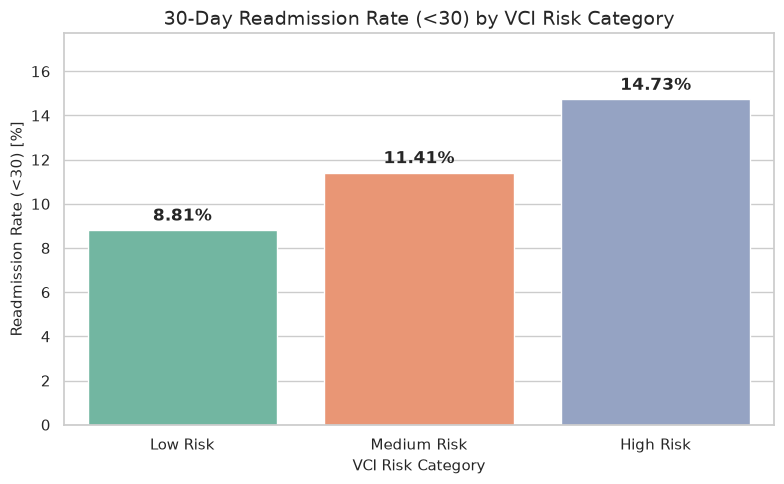

In [97]:
# calculate normalized readmission rates (%)
readmission_rates = (
    df.groupby('VCI_Risk_Category')['readmitted']
      .value_counts(normalize=True)
      .unstack()
      .reindex(index=risk_order, columns=['NO', '>30', '<30']) * 100
).round(2)

print("Readmission Rates (%) by VCI Risk Category:")
display(readmission_rates)

# extract <30 readmission rate
under_30_rates = readmission_rates['<30']

# plot bar chart
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=under_30_rates.index, y=under_30_rates.values, hue=under_30_rates.index, palette="Set2", legend=False)

# add percentage labels on bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=4, fontweight='bold')

plt.title("30-Day Readmission Rate (<30) by VCI Risk Category")
plt.xlabel("VCI Risk Category")
plt.ylabel("Readmission Rate (<30) [%]")
plt.ylim(0, under_30_rates.max() + 3)
plt.tight_layout()
plt.show()

## Step 4.6: Phase 4 Output Verification

We perform a final check on df to confirm that VCI_Score and VCI_Risk_Category are populated and save the updated dataset for downstream reporting.

In [98]:
print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print("Is VCI_Score added:", 'VCI_Score' in df.columns)
print("Is VCI_Risk_Category added:", 'VCI_Risk_Category' in df.columns)

# save final enriched dataset with VCI features
df.to_csv("data_files/diabetic_data_vci.csv", index=False)
print("Saved updated dataset to data_files/diabetic_data_vci.csv")

Total rows: 100114
Total columns: 52
Is VCI_Score added: True
Is VCI_Risk_Category added: True
Saved updated dataset to data_files/diabetic_data_vci.csv


## Step 4.7: Phase 4 Summary & Key Takeaways

In this phase, we engineered the *Vitality Complexity Index (VCI_Score)* and stratified all 100,114 valid patient encounters into three clinical risk tiers (Low Risk, Medium Risk, and High Risk).

Key findings from the VCI validation:

1. *Effective Risk Segregation:* The 30-day readmission rate (<30) increases steadily from Low Risk (VCI < 7) to Medium Risk (VCI 7–10) and peaks in the High Risk (VCI > 10) group, confirming that the LACE-based VCI algorithm successfully identifies patients at highest risk of early return.
2. *Clinical Decision Support:* Nursing leadership and discharge planners can use VCI_Risk_Category before discharge to prioritize targeted interventions—such as medication reviews and 48-hour post-discharge follow-up calls—for High Risk patients.
3. *Final Analytical Dataset:* All cleaned records, scraped primary diagnosis descriptions, and engineered VCI features are saved in diabetic_data_vci.csv for final executive reporting.